## Topic 4: Data Exploration

We are exploring whether Team C's high 2026 win rate is enough to consider it a championship contender. We start by checking the reported win rates, then look at the opponents each team faced, game location, preseason ratings, and past tournament results.

This notebook uses the cleaned data from `cleaning.ipynb`. Each question includes a table or graph and a short explanation of what we observe. 

#### Features used in the exploration

Some measures below come directly from the cleaned files; others are calculated by combining them. We use them to check whether Team C's win rate gives a fair picture of its strength.

| Feature | How it is made | Why we use it |
|---|---|---|
| Regular-season win rate | Wins divided by games played, excluding conference tournament games | Checks the headline comparison |
| Opponent preseason rating | Match each opponent to its rating for that season | Gives context about the teams each school faced |
| Schedule type | Compare both teams' conferences for that season | Separates conference from non-conference games |
| Game location | Read home, away, or neutral from the team's perspective | Checks whether location helps explain results |
| Tournament entry and wins | Match teams to tournament seeds and count their main-bracket wins | Checks how high-win teams performed in past tournaments |

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

project_root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
clean_dir = project_root / "cleaned_data"

files = {
    "teams": "teams.csv",
    "games": "regular_season_only.csv.gz",
    "conferences": "conferences.csv",
    "team_conferences": "team_conferences.csv",
    "preseason": "team_strength_preseason.csv",
    "seeds": "tournament_seeds.csv",
    "tournament_results": "tournament_results.csv"
}

data = {name: pd.read_csv(clean_dir / filename) for name, filename in files.items()}

teams = data["teams"]
games = data["games"]
conferences = data["conferences"]
team_conferences = data["team_conferences"]
preseason = data["preseason"]
seeds = data["seeds"]
tournament_results = data["tournament_results"]

file_summary = pd.DataFrame([
    {"File": filename, "Rows loaded": len(data[name])}
    for name, filename in files.items()
])

print("Loading cleaned data from:", clean_dir)
display(file_summary)

Loading cleaned data from: c:\Users\lsadi\Documents\GitHub\CSC-4913-Project-4\cleaned_data


,File,Rows loaded
0,teams.csv,360
1,regular_season_only.csv.gz,61559
2,conferences.csv,32
3,team_conferences.csv,4298
4,team_strength_preseason.csv,4298
5,tournament_seeds.csv,680
6,tournament_results.csv,670


In [19]:
figures_dir = project_root / "figures"
figures_dir.mkdir(parents=True, exist_ok=True)

# Keep Matplotlib's original show function if this cell is rerun.
original_show = getattr(plt.show, "_original_show", plt.show)
saved_figure_count = 0

def save_and_show(*args, **kwargs):
    global saved_figure_count

    for figure_number in plt.get_fignums():
        saved_figure_count += 1
        filename = f"figure_{saved_figure_count:02d}.png"
        path = figures_dir / filename
        plt.figure(figure_number).savefig(path, dpi=200, bbox_inches="tight")
        print(f"Saved: {path}")

    original_show(*args, **kwargs)

save_and_show._original_show = original_show
plt.show = save_and_show

### Question 1: Do the reported win rates match the data?

We check Team A's and Team C's 2026 regular-season records and show how many games each percentage is based on. Conference tournament games have already been excluded from the file used here.

,Team,School,Wins,Losses,Games,Win rate (%)
0,Team A,Ashford,21,9,30,70.00
1,Team C,Calloway State,24,4,28,85.71


Saved: c:\Users\lsadi\Documents\GitHub\CSC-4913-Project-4\figures\figure_01.png


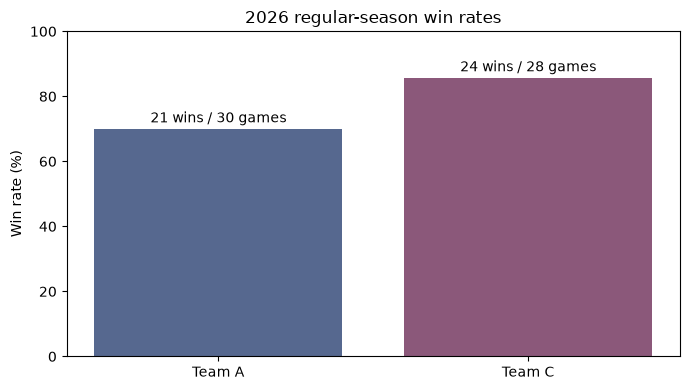

In [20]:
selected = teams.loc[
    teams["brief_alias"].isin(["Team A", "Team C"]),
    ["team_id", "team_name", "brief_alias"]
]

if len(selected) != 2 or set(selected["brief_alias"]) != {"Team A", "Team C"}:
    raise ValueError("Expected exactly one Team A and one Team C")

games_2026 = games.loc[games["season"] == 2026]

records = []
for team in selected.itertuples(index=False):
    wins = int((games_2026["w_team_id"] == team.team_id).sum())
    losses = int((games_2026["l_team_id"] == team.team_id).sum())
    total = wins + losses

    records.append({
        "Team": team.brief_alias,
        "School": team.team_name,
        "Wins": wins,
        "Losses": losses,
        "Games": total,
        "Win rate (%)": 100 * wins / total
    })

summary = pd.DataFrame(records).sort_values("Team")
display(summary.round({"Win rate (%)": 2}))

fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(summary["Team"], summary["Win rate (%)"], color=["#56688f", "#8b587a"])

ax.set_ylim(0, 100)
ax.set_ylabel("Win rate (%)")
ax.set_title("2026 regular-season win rates")

for bar, row in zip(bars, summary.itertuples(index=False)):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 2,
        f"{row.Wins} wins / {row.Games} games",
        ha="center"
    )

plt.tight_layout()
plt.show()

### Question 2: Did Team A and Team C face similar opponents?

A win counts the same in the standings regardless of the opponent. We compare the strength of the teams each school played in 2026 and look at conference and non-conference games separately. We use opponents' preseason ratings because those ratings were published before the games were played.

In [21]:
ratings_2026 = preseason.loc[
    preseason["season"] == 2026,
    ["team_id", "preseason_rank", "preseason_rating"]
].set_index("team_id")

conferences_2026 = team_conferences.loc[
    team_conferences["season"] == 2026,
    ["team_id", "conference_id"]
].set_index("team_id")["conference_id"]

team_games = []

for team in selected.itertuples(index=False):
    wins = games_2026.loc[
        games_2026["w_team_id"] == team.team_id,
        ["l_team_id"]
    ].rename(columns={"l_team_id": "opp_team_id"})
    wins["Won"] = 1

    losses = games_2026.loc[
        games_2026["l_team_id"] == team.team_id,
        ["w_team_id"]
    ].rename(columns={"w_team_id": "opp_team_id"})
    losses["Won"] = 0

    played = pd.concat([wins, losses], ignore_index=True)
    played["Team"] = team.brief_alias
    played["team_id"] = team.team_id
    team_games.append(played)

opponents = pd.concat(team_games, ignore_index=True)

opponents["Opponent rank"] = opponents["opp_team_id"].map(
    ratings_2026["preseason_rank"]
)
opponents["Opponent rating"] = opponents["opp_team_id"].map(
    ratings_2026["preseason_rating"]
)
opponents["Team conference"] = opponents["team_id"].map(conferences_2026)
opponents["Opponent conference"] = opponents["opp_team_id"].map(conferences_2026)

if opponents[[
    "Opponent rank", "Opponent rating",
    "Team conference", "Opponent conference"
]].isna().any().any():
    raise ValueError("Some opponents are missing a rating or conference")

opponents["Schedule"] = opponents.apply(
    lambda row: "Conference"
    if row["Team conference"] == row["Opponent conference"]
    else "Non-conference",
    axis=1
)

schedule_summary = opponents.groupby(
    ["Team", "Schedule"], as_index=False
).agg(
    Games=("Won", "size"),
    Wins=("Won", "sum"),
    Avg_opponent_rank=("Opponent rank", "mean"),
    Avg_opponent_rating=("Opponent rating", "mean")
)

schedule_summary["Win rate (%)"] = (
    100 * schedule_summary["Wins"] / schedule_summary["Games"]
)

display(schedule_summary.round({
    "Avg_opponent_rank": 1,
    "Avg_opponent_rating": 1,
    "Win rate (%)": 1
}))

,Team,Schedule,Games,Wins,Avg_opponent_rank,Avg_opponent_rating,Win rate (%)
0,Team A,Conference,18,13,58.9,11.2,72.2
1,Team A,Non-conference,12,8,132.2,5.0,66.7
2,Team C,Conference,16,16,311.6,-13.4,100.0
3,Team C,Non-conference,12,8,239.2,-5.6,66.7


#### How much did opponent strength vary?

An average can hide a mix of very strong and weak opponents. This box plot shows the spread of opponent preseason ratings for each team's conference and non-conference games.

Saved: c:\Users\lsadi\Documents\GitHub\CSC-4913-Project-4\figures\figure_02.png


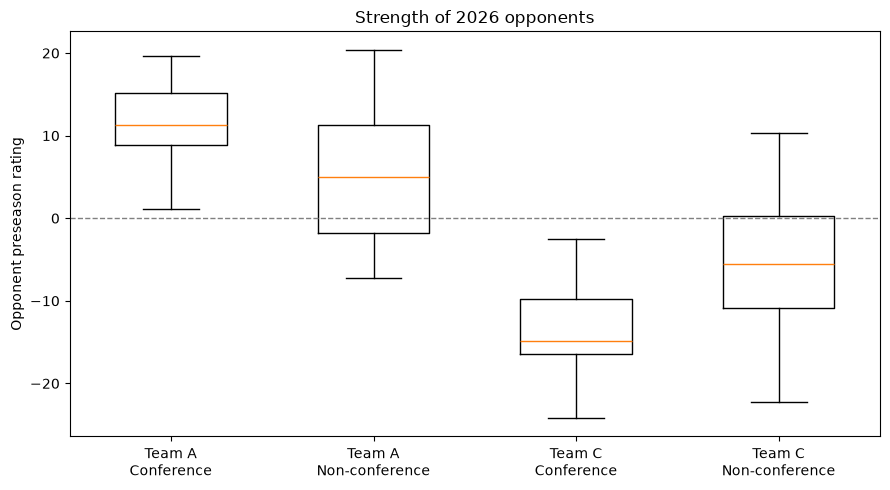

In [22]:
groups = [
    ("Team A", "Conference"),
    ("Team A", "Non-conference"),
    ("Team C", "Conference"),
    ("Team C", "Non-conference")
]

rating_values = [
    opponents.loc[
        (opponents["Team"] == team) &
        (opponents["Schedule"] == schedule),
        "Opponent rating"
    ].to_numpy()
    for team, schedule in groups
]

fig, ax = plt.subplots(figsize=(9, 5))
ax.boxplot(rating_values, widths=0.55)

ax.set_xticks(range(1, len(groups) + 1))
ax.set_xticklabels([f"{team}\n{schedule}" for team, schedule in groups])
ax.set_ylabel("Opponent preseason rating")
ax.set_title("Strength of 2026 opponents")
ax.axhline(0, color="gray", linewidth=1, linestyle="--")

plt.tight_layout()
plt.show()

#### Win rates against different opponent groups

We group opponents by preseason rank: top 100, ranks 101–200, and ranks 201 or higher numerically. For each group, we show both the win rate and the number of games. A percentage based on only one or two games needs particular care.

,Team,Opponent group,Wins,Games,Win rate (%)
0,Team A,Top 100,11,19,57.9
1,Team A,101–200,7,8,87.5
2,Team A,201+,3,3,100.0
3,Team C,Top 100,0,1,0.0
4,Team C,101–200,1,3,33.3
5,Team C,201+,23,24,95.8


Saved: c:\Users\lsadi\Documents\GitHub\CSC-4913-Project-4\figures\figure_03.png


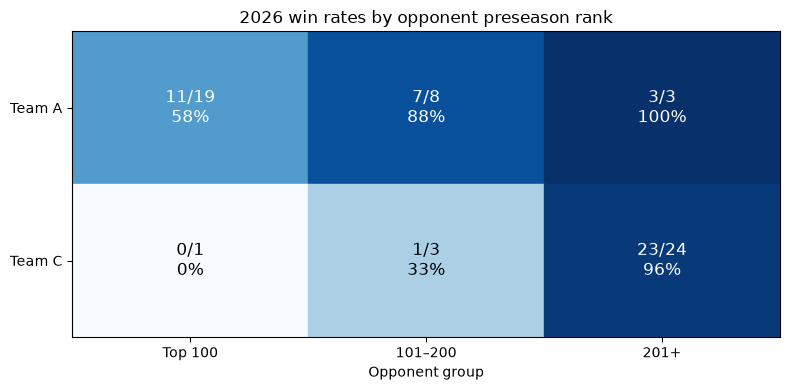

In [23]:
group_names = ["Top 100", "101–200", "201+"]

opponents["Opponent group"] = pd.cut(
    opponents["Opponent rank"],
    bins=[0, 100, 200, float("inf")],
    labels=group_names
)

strength_summary = opponents.groupby(
    ["Team", "Opponent group"],
    observed=False
).agg(
    Wins=("Won", "sum"),
    Games=("Won", "size")
).reset_index()

strength_summary["Win rate (%)"] = (
    100 * strength_summary["Wins"] / strength_summary["Games"]
)

display(strength_summary.round({"Win rate (%)": 1}))

fig, ax = plt.subplots(figsize=(8, 4))

for y, team in enumerate(["Team A", "Team C"]):
    for x, group in enumerate(group_names):
        row = strength_summary.loc[
            (strength_summary["Team"] == team) &
            (strength_summary["Opponent group"] == group)
        ].iloc[0]

        rate = row["Win rate (%)"]
        ax.add_patch(plt.Rectangle(
            (x - 0.5, y - 0.5), 1, 1,
            color=plt.cm.Blues(rate / 100)
        ))
        ax.text(
            x, y,
            f"{row['Wins']}/{row['Games']}\n{rate:.0f}%",
            ha="center", va="center",
            color="white" if rate >= 55 else "black",
            fontsize=12
        )

ax.set_xlim(-0.5, 2.5)
ax.set_ylim(1.5, -0.5)
ax.set_xticks(range(3), group_names)
ax.set_yticks(range(2), ["Team A", "Team C"])
ax.set_title("2026 win rates by opponent preseason rank")
ax.set_xlabel("Opponent group")

plt.tight_layout()
plt.show()

**Observation:** The teams faced very different schedules. Team A played 19 games against top-100 preseason opponents, while Team C played only one. Team C played 24 games against teams ranked 201 or higher, compared with three for Team A. Team C's higher overall win rate may therefore be affected by opponent strength. The win rates in groups with only one or three games are too uncertain to interpret on their own.

### Question 3: Does game location affect the comparison?

Home teams tend to win more often, so we compare Team A's and Team C's 2026 records at home, away, and at neutral sites. We show the number of games as well as the win rate for each location.

,Team,Location,Wins,Losses,Games,Win rate (%)
1,Team A,Home,13,1,14,92.9
0,Team A,Away,8,4,12,66.7
2,Team A,Neutral,0,4,4,0.0
4,Team C,Home,14,0,14,100.0
3,Team C,Away,9,2,11,81.8
5,Team C,Neutral,1,2,3,33.3


Saved: c:\Users\lsadi\Documents\GitHub\CSC-4913-Project-4\figures\figure_04.png


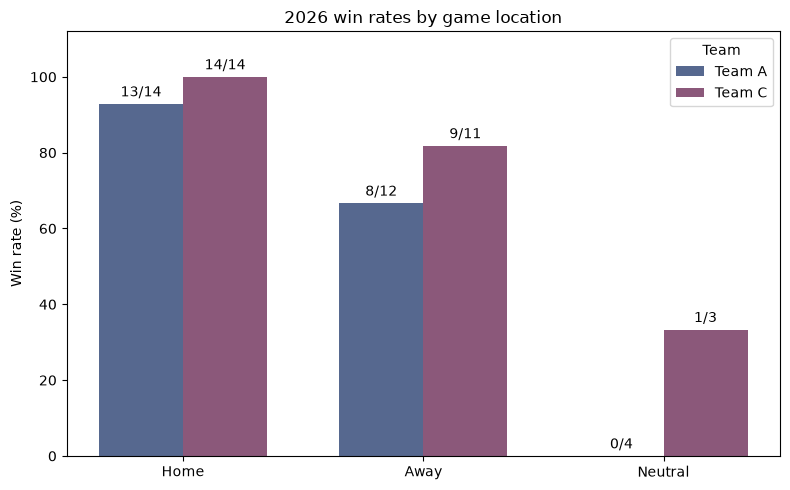

In [24]:
location_games = []

for team in selected.itertuples(index=False):
    wins = games_2026.loc[
        games_2026["w_team_id"] == team.team_id,
        ["w_loc"]
    ].copy()
    wins["Location"] = wins["w_loc"].map({
        "H": "Home", "A": "Away", "N": "Neutral"
    })
    wins["Won"] = 1

    losses = games_2026.loc[
        games_2026["l_team_id"] == team.team_id,
        ["w_loc"]
    ].copy()
    losses["Location"] = losses["w_loc"].map({
        "H": "Away", "A": "Home", "N": "Neutral"
    })
    losses["Won"] = 0

    played = pd.concat([wins, losses], ignore_index=True)
    played["Team"] = team.brief_alias
    location_games.append(played)

by_location = pd.concat(location_games, ignore_index=True)

if by_location["Location"].isna().any():
    raise ValueError("Some 2026 game locations are missing or invalid")

location_summary = by_location.groupby(
    ["Team", "Location"], as_index=False
).agg(
    Wins=("Won", "sum"),
    Games=("Won", "size")
)

location_summary["Losses"] = (
    location_summary["Games"] - location_summary["Wins"]
)
location_summary["Win rate (%)"] = (
    100 * location_summary["Wins"] / location_summary["Games"]
)

location_order = ["Home", "Away", "Neutral"]
location_summary["Location"] = pd.Categorical(
    location_summary["Location"],
    categories=location_order,
    ordered=True
)

location_summary = location_summary.sort_values(["Team", "Location"])

display(location_summary[
    ["Team", "Location", "Wins", "Losses", "Games", "Win rate (%)"]
].round({"Win rate (%)": 1}))

fig, ax = plt.subplots(figsize=(8, 5))
locations = ["Home", "Away", "Neutral"]
width = 0.35

for team, offset, color in [
    ("Team A", -width / 2, "#56688f"),
    ("Team C",  width / 2, "#8b587a")
]:
    rows = location_summary.loc[
        location_summary["Team"] == team
    ].set_index("Location").reindex(locations)

    positions = [i + offset for i in range(len(locations))]
    bars = ax.bar(positions, rows["Win rate (%)"], width, label=team, color=color)

    for bar, (_, row) in zip(bars, rows.iterrows()):
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 2,
            f"{int(row['Wins'])}/{int(row['Games'])}",
            ha="center"
        )

ax.set_xticks(range(len(locations)), locations)
ax.set_ylim(0, 112)
ax.set_ylabel("Win rate (%)")
ax.set_title("2026 win rates by game location")
ax.legend(title="Team")

plt.tight_layout()
plt.show()

**Observation:** Both teams played 14 home games, so Team C's higher overall win rate is not simply because it played many more games at home. The neutral-site groups contain only a few games, so their percentages are less reliable.

### Question 4: Was Team C's 2026 season unexpected?

We first look at Team C’s preseason rank and rating from 2015 to 2026. These were published before each season began, so they show how the team was viewed before its games were played.

,Season,Preseason rank,Preseason rating
309,2015,310,-11.3
647,2016,293,-8.9
1019,2017,310,-11.4
1379,2018,314,-11.5
1722,2019,300,-10.1
2085,2020,305,-10.4
2394,2021,256,-6.1
2803,2022,306,-10.1
3130,2023,273,-7.1
3478,2024,261,-5.5


Saved: c:\Users\lsadi\Documents\GitHub\CSC-4913-Project-4\figures\figure_10.png


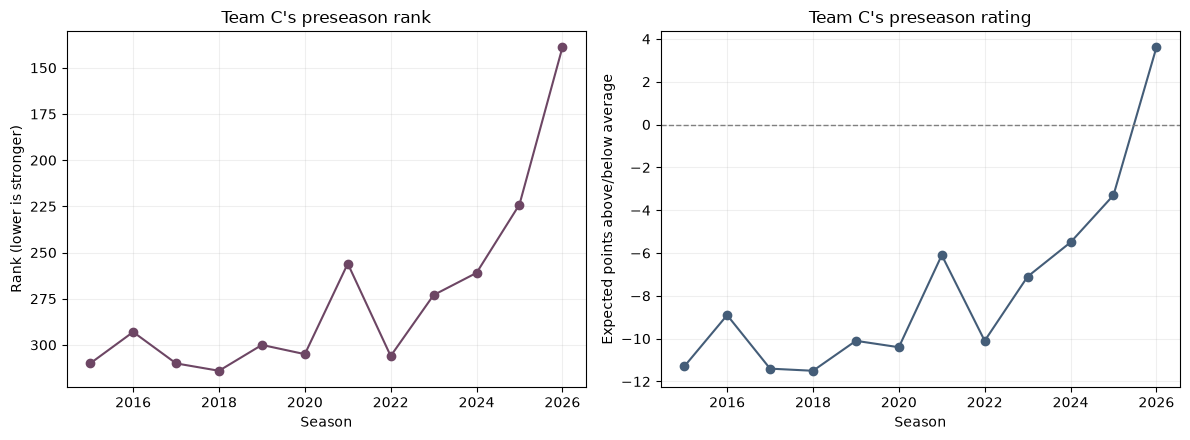

In [33]:
team_c_id = teams.loc[
    teams["brief_alias"].eq("Team C"), "team_id"
].iloc[0]

c_history = (
    preseason.loc[preseason["team_id"].eq(team_c_id)]
    .sort_values("season")
    .copy()
)

display(
    c_history[
        ["season", "preseason_rank", "preseason_rating"]
    ].rename(columns={
        "season": "Season",
        "preseason_rank": "Preseason rank",
        "preseason_rating": "Preseason rating"
    })
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].plot(
    c_history["season"],
    c_history["preseason_rank"],
    marker="o",
    color="#6d4664"
)
axes[0].invert_yaxis()  # Rank 1 is the strongest.
axes[0].set_title("Team C's preseason rank")
axes[0].set_xlabel("Season")
axes[0].set_ylabel("Rank (lower is stronger)")
axes[0].grid(alpha=0.2)

axes[1].plot(
    c_history["season"],
    c_history["preseason_rating"],
    marker="o",
    color="#445d78"
)
axes[1].axhline(0, color="gray", linestyle="--", linewidth=1)
axes[1].set_title("Team C's preseason rating")
axes[1].set_xlabel("Season")
axes[1].set_ylabel("Expected points above/below average")
axes[1].grid(alpha=0.2)

plt.tight_layout()
plt.show()

#### Historical context for preseason ratings

To judge whether Team C's 2026 result was unusual, we compare preseason ratings with regular-season win rates for all teams from 2015 through 2025. Each point on the chart represents one team in one season. The larger points show the average result for five groups of preseason ratings. Team C's 2026 result is shown separately.

In [34]:
# Give each team one row for every regular-season game it played.
winner_rows = (
    games[["season", "w_team_id"]]
    .rename(columns={"w_team_id": "team_id"})
    .assign(Won=1)
)

loser_rows = (
    games[["season", "l_team_id"]]
    .rename(columns={"l_team_id": "team_id"})
    .assign(Won=0)
)

team_seasons = (
    pd.concat([winner_rows, loser_rows], ignore_index=True)
    .groupby(["season", "team_id"], as_index=False)
    .agg(Wins=("Won", "sum"), Games=("Won", "size"))
)

team_seasons["Win rate (%)"] = (
    100 * team_seasons["Wins"] / team_seasons["Games"]
)

# Match each record to the rating published before that season.
team_seasons = team_seasons.merge(
    preseason[
        ["season", "team_id", "preseason_rank", "preseason_rating"]
    ],
    on=["season", "team_id"],
    how="inner",
    validate="one_to_one"
)

rating_history = team_seasons.loc[
    team_seasons["season"] < 2026
].copy()

team_c_2026 = team_seasons.loc[
    team_seasons["season"].eq(2026)
    & team_seasons["team_id"].eq(team_c_id)
].iloc[0]

rating_correlation = rating_history[
    "preseason_rating"
].corr(rating_history["Win rate (%)"])

rating_history["Rating group"] = pd.qcut(
    rating_history["preseason_rating"],
    q=5,
    labels=[
        "Lowest fifth",
        "Second fifth",
        "Middle fifth",
        "Fourth fifth",
        "Highest fifth"
    ]
)

rating_groups = (
    rating_history
    .groupby("Rating group", observed=False)
    .agg(
        Team_seasons=("team_id", "size"),
        Average_preseason_rating=("preseason_rating", "mean"),
        Average_win_rate=("Win rate (%)", "mean")
    )
)

print(f"Historical team-seasons: {len(rating_history):,}")
print(f"Correlation between rating and win rate: {rating_correlation:.2f}")
print(
    f"Team C, 2026: {int(team_c_2026['Wins'])} wins in "
    f"{int(team_c_2026['Games'])} games; "
    f"{team_c_2026['Win rate (%)']:.1f}% win rate"
)

display(rating_groups.round(1))

Historical team-seasons: 3,938
Correlation between rating and win rate: 0.63
Team C, 2026: 24 wins in 28 games; 85.7% win rate


,Team_seasons,Average_preseason_rating,Average_win_rate
Rating group,,,
Lowest fifth,790,-13.9,34.1
Second fifth,800,-5.3,46.3
Middle fifth,782,0.3,50.1
Fourth fifth,782,5.9,54.6
Highest fifth,784,13.3,64.8


Saved: c:\Users\lsadi\Documents\GitHub\CSC-4913-Project-4\figures\figure_11.png


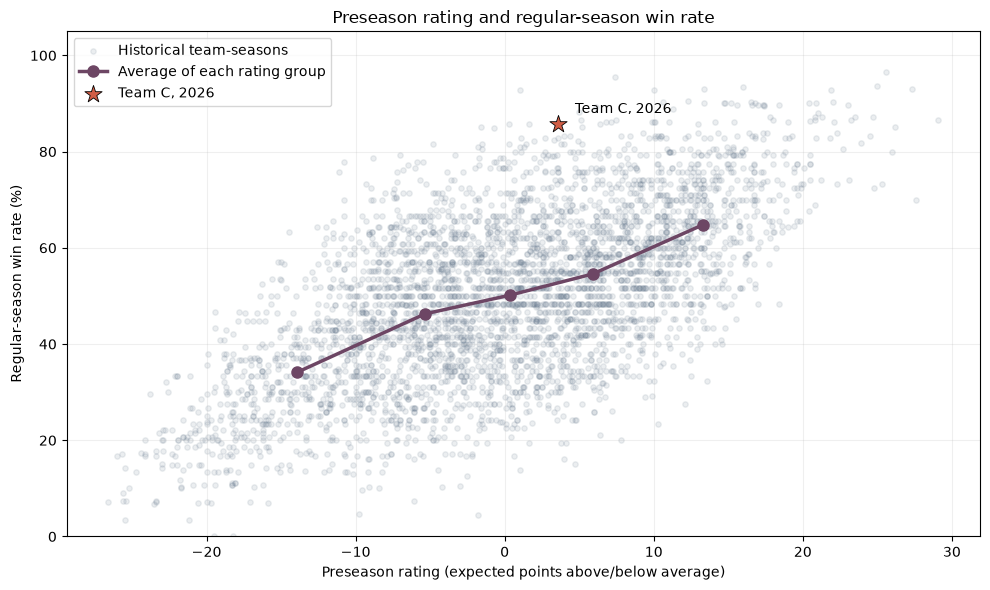

In [35]:
fig, ax = plt.subplots(figsize=(10, 6))

ax.scatter(
    rating_history["preseason_rating"],
    rating_history["Win rate (%)"],
    s=15,
    alpha=0.12,
    color="#60748a",
    label="Historical team-seasons"
)

ax.plot(
    rating_groups["Average_preseason_rating"],
    rating_groups["Average_win_rate"],
    marker="o",
    markersize=8,
    linewidth=2.5,
    color="#6d4664",
    label="Average of each rating group"
)

ax.scatter(
    team_c_2026["preseason_rating"],
    team_c_2026["Win rate (%)"],
    s=170,
    marker="*",
    color="#d15d45",
    edgecolor="black",
    linewidth=0.6,
    zorder=5,
    label="Team C, 2026"
)

ax.annotate(
    "Team C, 2026",
    (
        team_c_2026["preseason_rating"],
        team_c_2026["Win rate (%)"]
    ),
    xytext=(12, 8),
    textcoords="offset points"
)

ax.set_title("Preseason rating and regular-season win rate")
ax.set_xlabel("Preseason rating (expected points above/below average)")
ax.set_ylabel("Regular-season win rate (%)")
ax.set_ylim(0, 105)
ax.grid(alpha=0.2)
ax.legend()
plt.tight_layout()
plt.show()

#### Teams with similar preseason ranks in 2026

Team C was ranked 139th before the season. We compare its win rate with teams ranked **101st–200th** in the same preseason publication. This gives us a more direct comparison than looking at all teams together. The group is broad, so it provides context rather than an exact prediction for a rank of 139.

Teams in rank 101–200 group: 100
Team C's win-rate position in this group: 1
Group median win rate: 50.8%


,Team,Preseason rank,Preseason rating,Wins,Games,Win rate (%)
0,Calloway State,139,3.6,24,28,85.7
1,Northern Keswick,124,5.2,24,29,82.8
2,Elkin,123,5.2,24,30,80.0
3,Dalton A&M,151,2.5,24,30,80.0
4,Pendleton,141,3.1,23,29,79.3
5,Easton State,125,5.1,22,28,78.6
6,Halston,102,7.5,22,28,78.6
7,Pemberton State,164,1.6,21,27,77.8
8,Saint Finian,101,7.5,22,29,75.9
9,Easton,148,2.7,21,28,75.0


Saved: c:\Users\lsadi\Documents\GitHub\CSC-4913-Project-4\figures\figure_12.png


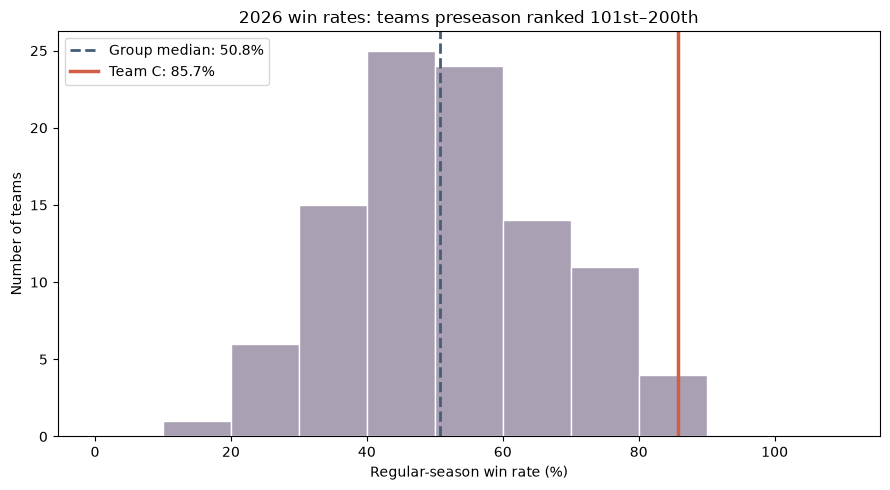

In [36]:
peers_2026 = (
    team_seasons.loc[
        team_seasons["season"].eq(2026)
        & team_seasons["preseason_rank"].between(101, 200)
    ]
    .merge(teams[["team_id", "team_name"]], on="team_id")
    .sort_values("Win rate (%)", ascending=False)
    .reset_index(drop=True)
)

team_c_position = (
    peers_2026.index[peers_2026["team_id"].eq(team_c_id)][0] + 1
)

peer_median = peers_2026["Win rate (%)"].median()

print(f"Teams in rank 101–200 group: {len(peers_2026)}")
print(f"Team C's win-rate position in this group: {team_c_position}")
print(f"Group median win rate: {peer_median:.1f}%")

display(
    peers_2026[
        [
            "team_name",
            "preseason_rank",
            "preseason_rating",
            "Wins",
            "Games",
            "Win rate (%)"
        ]
    ]
    .head(10)
    .rename(columns={
        "team_name": "Team",
        "preseason_rank": "Preseason rank",
        "preseason_rating": "Preseason rating"
    })
    .round({"Win rate (%)": 1})
)

fig, ax = plt.subplots(figsize=(9, 5))

ax.hist(
    peers_2026["Win rate (%)"],
    bins=range(0, 111, 10),
    color="#a9a0b3",
    edgecolor="white"
)

ax.axvline(
    peer_median,
    color="#445d78",
    linestyle="--",
    linewidth=2,
    label=f"Group median: {peer_median:.1f}%"
)

ax.axvline(
    team_c_2026["Win rate (%)"],
    color="#d15d45",
    linewidth=2.5,
    label=f"Team C: {team_c_2026['Win rate (%)']:.1f}%"
)

ax.set_title("2026 win rates: teams preseason ranked 101st–200th")
ax.set_xlabel("Regular-season win rate (%)")
ax.set_ylabel("Number of teams")
ax.legend()
plt.tight_layout()
plt.show()

**Observation:** Team C's preseason rank improved from **310th in 2015** to **139th in 2026**, and its rating rose from **−11.3 to +3.6**. This suggests expectations for the team had improved before the 2026 season.

Across all team-seasons from 2015–2025, preseason rating and regular-season win rate had a positive correlation of about **0.63**. Team C then won **24 of 28 games (85.7%)** in 2026, well above the broad historical pattern near its preseason rating. It had the highest win rate among the **100 teams ranked 101st–200th** before the 2026 season; that group's median was about **50.8%**.

Team C therefore exceeded preseason expectations. This tells us its season was unusual, but it does not by itself establish how it will perform against national-tournament opponents.

### Question 5 — Does a high regular-season win rate usually lead to tournament success?

We use seasons with completed national tournaments (2015–2019 and 2021–2025). For each team and season, we calculate its regular-season win rate and check whether it was selected for the national tournament. We then count its wins in the main tournament bracket.

The four win-rate groups are **under 60%**, **60% to under 70%**, **70% to under 80%**, and **80% or higher**. We show both the chance of reaching the tournament and what happened *among teams that reached it*. First Four games are excluded from the bracket-win count so each team is compared on the same main-bracket measure.

In [28]:
completed_seasons = sorted(
    set(tournament_results["season"]) & set(seeds["season"])
)

past_games = games.loc[games["season"].isin(completed_seasons)]

# Give each team one row for each regular-season game it played.
winner_rows = (
    past_games[["season", "w_team_id"]]
    .rename(columns={"w_team_id": "team_id"})
    .assign(Won=1)
)

loser_rows = (
    past_games[["season", "l_team_id"]]
    .rename(columns={"l_team_id": "team_id"})
    .assign(Won=0)
)

historical = (
    pd.concat([winner_rows, loser_rows], ignore_index=True)
    .groupby(["season", "team_id"], as_index=False)
    .agg(Wins=("Won", "sum"), Games=("Won", "size"))
)

historical["Win rate (%)"] = (
    100 * historical["Wins"] / historical["Games"]
)

# A seed means that the team entered the national tournament.
historical = historical.merge(
    seeds.loc[
        seeds["season"].isin(completed_seasons),
        ["season", "team_id", "seed"]
    ],
    on=["season", "team_id"],
    how="left",
    validate="one_to_one"
)

historical["Selected"] = historical["seed"].notna()

# Day 136 and later are games in the main bracket.
bracket_wins = (
    tournament_results.loc[
        tournament_results["day_num"] >= 136
    ]
    .groupby(["season", "w_team_id"])
    .size()
    .rename("Bracket wins")
    .reset_index()
    .rename(columns={"w_team_id": "team_id"})
)

historical = historical.merge(
    bracket_wins,
    on=["season", "team_id"],
    how="left",
    validate="one_to_one"
)

historical["Bracket wins"] = (
    historical["Bracket wins"].fillna(0).astype(int)
)
historical["Won a bracket game"] = historical["Bracket wins"] >= 1

band_order = ["Under 60%", "60–<70%", "70–<80%", "80%+"]

historical["Win-rate group"] = pd.cut(
    historical["Win rate (%)"],
    bins=[-0.01, 60, 70, 80, float("inf")],
    labels=band_order,
    right=False
)

print("Completed seasons:", completed_seasons)
print("Team-seasons analyzed:", len(historical))
print("Tournament entrants:", historical["Selected"].sum())

Completed seasons: [2015, 2016, 2017, 2018, 2019, 2021, 2022, 2023, 2024, 2025]
Team-seasons analyzed: 3580
Tournament entrants: 680


#### Tournament entry and results by win-rate group

The first table includes **every team-season**, including teams that did not make the tournament. The second table includes **tournament entrants only**. This distinction matters because a team cannot win a tournament game if it was not selected.

In [29]:
all_teams_summary = (
    historical
    .groupby("Win-rate group", observed=False)
    .agg(
        Team_seasons=("team_id", "size"),
        Selected=("Selected", "sum"),
        Won_bracket_game=("Won a bracket game", "sum")
    )
)

all_teams_summary["Selected (%)"] = (
    100 * all_teams_summary["Selected"]
    / all_teams_summary["Team_seasons"]
)

all_teams_summary["Won bracket game (%)"] = (
    100 * all_teams_summary["Won_bracket_game"]
    / all_teams_summary["Team_seasons"]
)

selected_summary = (
    historical.loc[historical["Selected"]]
    .groupby("Win-rate group", observed=False)
    .agg(
        Entrants=("team_id", "size"),
        Won_bracket_game=("Won a bracket game", "sum"),
        Average_bracket_wins=("Bracket wins", "mean")
    )
)

selected_summary["Won bracket game (%)"] = (
    100 * selected_summary["Won_bracket_game"]
    / selected_summary["Entrants"]
)

print("All teams:")
display(all_teams_summary.round(1))

print("Tournament entrants only:")
display(selected_summary.round(1))

All teams:


,Team_seasons,Selected,Won_bracket_game,Selected (%),Won bracket game (%)
Win-rate group,,,,,
Under 60%,2505,158,56,6.3,2.2
60–<70%,592,202,81,34.1,13.7
70–<80%,340,211,105,62.1,30.9
80%+,143,109,78,76.2,54.5


Tournament entrants only:


,Entrants,Won_bracket_game,Average_bracket_wins,Won bracket game (%)
Win-rate group,,,,
Under 60%,158,56,0.6,35.4
60–<70%,202,81,0.7,40.1
70–<80%,211,105,0.9,49.8
80%+,109,78,1.7,71.6


Saved: c:\Users\lsadi\Documents\GitHub\CSC-4913-Project-4\figures\figure_08.png


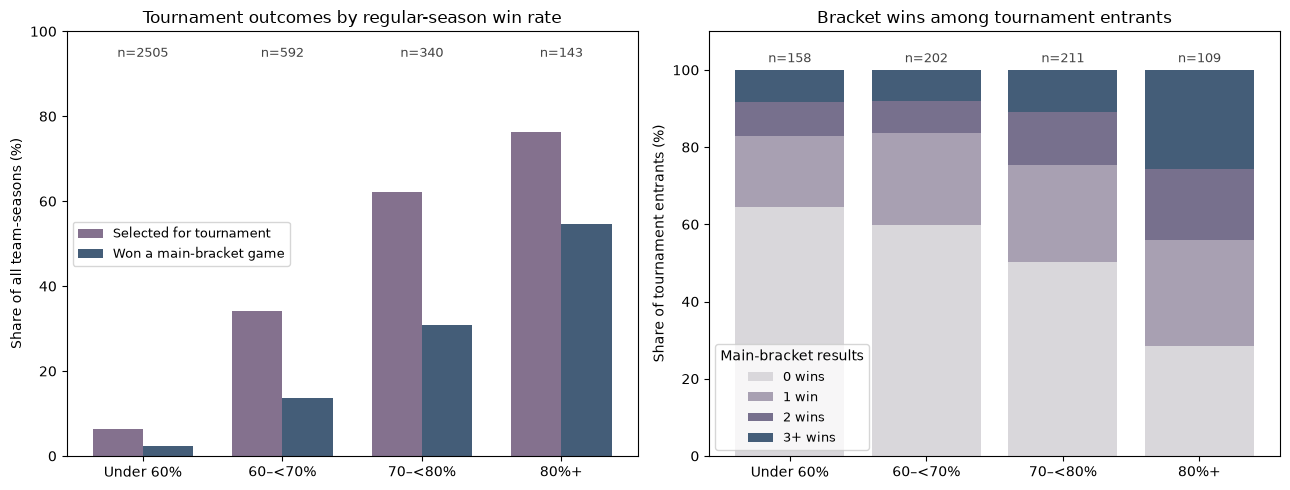

In [30]:
import numpy as np

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Left: How often did teams enter and win a game?
x = np.arange(len(band_order))
width = 0.36

axes[0].bar(
    x - width / 2,
    all_teams_summary["Selected (%)"],
    width,
    label="Selected for tournament",
    color="#84718e"
)

axes[0].bar(
    x + width / 2,
    all_teams_summary["Won bracket game (%)"],
    width,
    label="Won a main-bracket game",
    color="#445d78"
)

axes[0].set_xticks(x, band_order)
axes[0].set_ylim(0, 100)
axes[0].set_ylabel("Share of all team-seasons (%)")
axes[0].set_title("Tournament outcomes by regular-season win rate")
axes[0].legend(fontsize=9)

for i, count in enumerate(all_teams_summary["Team_seasons"]):
    axes[0].text(
        i, 94, f"n={count}",
        ha="center", fontsize=9, color="#444444"
    )

# Right: Among entrants, how many main-bracket games did they win?
entrants = historical.loc[historical["Selected"]].copy()

entrants["Win category"] = np.select(
    [
        entrants["Bracket wins"].eq(0),
        entrants["Bracket wins"].eq(1),
        entrants["Bracket wins"].eq(2)
    ],
    ["0 wins", "1 win", "2 wins"],
    default="3+ wins"
)

category_order = ["0 wins", "1 win", "2 wins", "3+ wins"]

distribution = pd.crosstab(
    entrants["Win-rate group"],
    entrants["Win category"]
).reindex(
    index=band_order,
    columns=category_order,
    fill_value=0
)

distribution_pct = (
    distribution.div(distribution.sum(axis=1), axis=0) * 100
)

colors = ["#d9d7db", "#a8a0b2", "#77708d", "#445d78"]
bottom = np.zeros(len(band_order))

for category, color in zip(category_order, colors):
    values = distribution_pct[category].to_numpy()
    axes[1].bar(
        band_order,
        values,
        bottom=bottom,
        label=category,
        color=color
    )
    bottom += values

axes[1].set_ylim(0, 100)
axes[1].set_ylabel("Share of tournament entrants (%)")
axes[1].set_title("Bracket wins among tournament entrants")
axes[1].legend(title="Main-bracket results", fontsize=9)

for i, count in enumerate(distribution.sum(axis=1)):
    axes[1].text(
        i, 102, f"n={count}",
        ha="center", fontsize=9, color="#444444"
    )

axes[1].set_ylim(0, 110)

plt.tight_layout()
plt.show()

**Observation:** In the ten completed tournaments, teams with higher regular-season win rates were more likely to enter the tournament and win a main-bracket game. Among teams with an **80% or higher** regular-season win rate, **109 of 143** entered the tournament, and **78 of 143** won at least one main-bracket game. Among the 109 entrants in that group, **78 (71.6%)** won a main-bracket game.

A high win rate is therefore a useful historical sign, but it does not guarantee a championship. These results describe past teams as a group; they do not tell us how Team C will perform in the unplayed 2026 tournament.

## Exploration takeaway

Team C's 85.7% regular-season win rate is confirmed, but Team C faced substantially weaker opponents than Team A. The location, preseason, and historical tournament comparisons add context, but a high win rate alone does not establish Team C as a clear championship favorite. We will test whether schedule strength explains the apparent advantage.
